# code_034 · Reproducibility and provenance

**Book:** section 7.3. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_07_GUIDE.md), [execution evidence](../CHAPTER_07_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_034). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=734;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 734


<a id="snapshot"></a>
## Preserve the actual input, not only its generator seed

Generate 360 dimensionless sensor values with an AR(1) term .82, a fixed sinusoidal term .1*sin(2*pi*t/24), and independent noise sd .15. Three observed lags predict the next sensor value. The first 200 windows train, the next 60 develop and the last 97 assess. This is rolling one-step prediction: each earlier observation is available before the next forecast, but model weights never update on final cases. It is not a fixed-origin 97-step forecast.

The in-memory snapshot consists of a sorted JSON schema header and little-endian float64 bytes in C order. Hash both together. The committed execution summary retains the full snapshot as base64 alongside its hash, so readers can recover the actual reference bytes. No ordinary-run file is read or written. A hash identifies bytes and schema under a declared encoding; it cannot establish data correctness or legal provenance.


In [2]:
import hashlib,base64
from sklearn.ensemble import RandomForestRegressor
def generate(seed):
 r=np.random.default_rng(seed);v=np.zeros(360)
 for t in range(1,360):v[t]=.82*v[t-1]+.1*np.sin(2*np.pi*t/24)+r.normal(0,.15)
 return v
def pack(v):
 header=json.dumps({'dtype':'<f8','shape':[len(v)],'order':'C','units':'sensor/reference'},sort_keys=True,separators=(',',':')).encode()
 return header+bytes([10])+np.asarray(v,dtype='<f8').tobytes()
def unpack(snapshot):
 header,payload=snapshot.split(bytes([10]),1);schema=json.loads(header);v=np.frombuffer(payload,dtype=schema['dtype']).copy()
 assert list(v.shape)==schema['shape']
 return v
values=generate(SEED);snapshot=pack(values);digest=hashlib.sha256(snapshot).hexdigest();replayed=unpack(snapshot)
assert np.array_equal(values,replayed) and pack(replayed)==snapshot
mutated=values.copy();mutated[10]+=.1;bad_snapshot=pack(mutated)
assert hashlib.sha256(bad_snapshot).hexdigest()!=digest
rejected=False
try:assert hashlib.sha256(bad_snapshot).hexdigest()==digest
except AssertionError:rejected=True
assert rejected
RESULTS['snapshot_base64']=base64.b64encode(snapshot).decode();assert base64.b64decode(RESULTS['snapshot_base64'])==snapshot
RESULTS['snapshot_sha256']=digest;RESULTS['mutated_snapshot_rejected']=rejected


<a id="program"></a>
## Code, configuration, dependencies and execution conditions

The literal program below is the critical training function that is executed and hashed. This hash covers that function, not the entire notebook, data generator or environment. The published notebook commit is recorded separately in the execution report. Record all fixed model controls used here, actual package versions, seed and CPU. A seed does not constrain changes in libraries, floating-point kernels or hardware. The serial CPU setting is part of the repeatability scope, not a promise across other systems.


In [3]:
MODEL_PROGRAM="""def fit_predict(values, seed):
    X = np.column_stack([values[2:-1], values[1:-2], values[:-3]])
    y = values[3:]
    model = RandomForestRegressor(n_estimators=40, max_depth=4,
        min_samples_leaf=3, criterion='squared_error', bootstrap=True,
        random_state=seed, n_jobs=1)
    model.fit(X[:200], y[:200])
    return model.predict(X), X, y
"""
exec(MODEL_PROGRAM)
config={'data_sha256':digest,'critical_program_sha256':hashlib.sha256(MODEL_PROGRAM.encode()).hexdigest(),'seed':SEED,'n_estimators':40,'max_depth':4,'min_samples_leaf':3,'criterion':'squared_error','bootstrap':True,'n_jobs':1,'train_windows':200,'development_windows':60,'final_windows':97,'horizon':'rolling one step','scaling':'none; tree split model','versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU'}
config_hash=hashlib.sha256(json.dumps(config,sort_keys=True,separators=(',',':')).encode()).hexdigest()
pred,X,y=fit_predict(unpack(snapshot),SEED);again,X2,y2=fit_predict(unpack(snapshot),SEED)
assert np.array_equal(pred,again) and np.array_equal(X,X2) and np.array_equal(y,y2)
assert X.shape==(357,3) and len(y[260:])==97
assert np.array_equal(X[:,0],values[2:-1])
RESULTS['configuration_sha256']=config_hash;RESULTS['critical_program_sha256']=config['critical_program_sha256'];RESULTS['exact_replay']=bool(np.array_equal(pred,again));RESULTS['configuration']=config
print('Data hash:',digest,'configuration hash:',config_hash,'exact replay:',RESULTS['exact_replay'])


Data hash: 11117b9985b5ee0efc7ed779a1e7c489e0f8c89fea2b57a1b0579aad372fc7dc configuration hash: ddcd580016f82388094f0a05fcebe3eb5a354c66ecfb9a7d67c76084f2108bcf exact replay: True


<a id="variation"></a>
## Repeatability, seed variation and new evidence

Five predeclared alternative model seeds measure development variation on the same snapshot. None is selected as best. The original named seed remains fixed for final assessment. Then generate an independent new series and rerun the same training procedure; this is replication within the same simulator, not independent field replication or a different physical population.


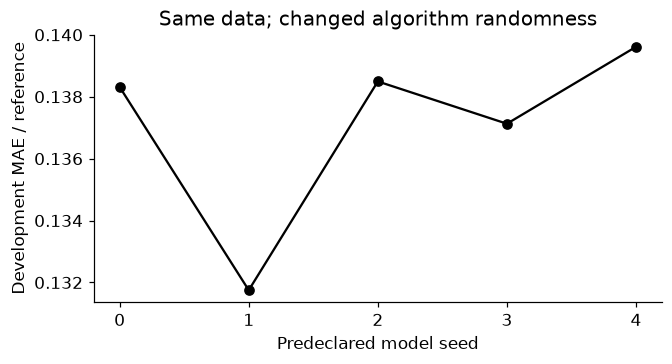

In [4]:
seeds=[0,1,2,3,4];dev_errors=[]
for seed in seeds:
 p,_,_=fit_predict(unpack(snapshot),seed);dev_errors.append(float(np.mean(abs(p[200:260]-y[200:260]))))
assert len(dev_errors)==5 and np.isfinite(dev_errors).all()
replica=pack(generate(SEED+10000));replica_digest=hashlib.sha256(replica).hexdigest();replica_pred,replica_X,replica_y=fit_predict(unpack(replica),SEED)
assert replica_digest!=digest and not np.array_equal(replica_pred,pred)
fig,ax=plt.subplots(figsize=(6,3.2));ax.plot(seeds,dev_errors,'ko-');ax.set(xticks=seeds,xlabel='Predeclared model seed',ylabel='Development MAE / reference',title='Same data; changed algorithm randomness');plt.show()
RESULTS['development_MAE_by_seed']=dict(zip(map(str,seeds),dev_errors));RESULTS['replication_snapshot_sha256']=replica_digest


<a id="final"></a>
## Fixed forecast, actual final outcomes

Open the original and independently generated series' final windows without changing settings. Persistence predicts the most recent observed value. The plot shows the original rolling forecasts; it does not feed future unknown values into a fixed-origin forecast. Timing and version information are needed to understand that distinction.


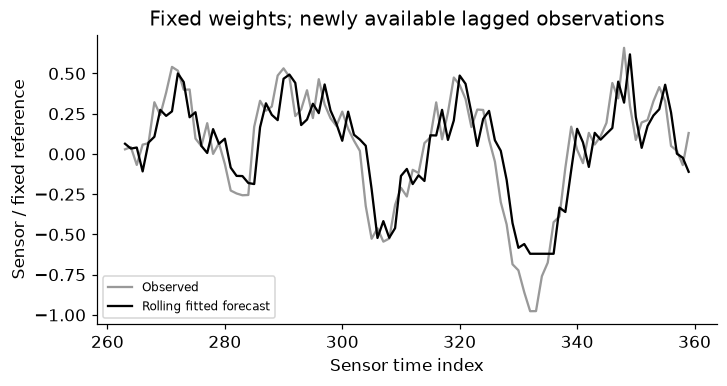

{'snapshot_base64': 'eyJkdHlwZSI6IjxmOCIsIm9yZGVyIjoiQyIsInNoYXBlIjpbMzYwXSwidW5pdHMiOiJzZW5zb3IvcmVmZXJlbmNlIn0KAAAAAAAAAAAFKuDxom3JP1NyYWpxI9U/34ZNwQz53D+nk2izPwDNP+A1Ov9Chpi/qJjuQNExsj/2cCCnWGDeP2pBYHZ1KN4/QK1f1u8+4z+KUQjJWrHmP6R83flRzOQ/5Gxmw+rL1T+8KFOoQUfUPwLAJiXVs8A/jMw9fdteuL+YoS2zbxHZv3amzJZGk+G/rHGz9tVG5L9ANm9+rrXkv2NjWOchTeW/6dFcnxX16L+IErZHexHnv1HBvHqDquS/I7Cv2Poz4r/LfnmlRJvjv/Mjj3b6Ytq/XitaVQel078AumCXEgCcP7VKF5whra0/eHykVPa9xD8W8QrMeJe2Pw1m3bq6FME/wH9e/iSclr/PX24vhP/OP54UAsbZAMk/1ST9EyH3uj/i0cVG/bOuP1qBA94Cp7C/Gp3vvToQyb81FKiHT+TVv6J0He/+oeC/QTJqa0yv5L+MLRF061rkv391WBOS3+O/I7DsVaK36L801Q2YEfHkv32CYd4hRtG/8pYCbmz3yr+m8s06s5nSP6VBcJqPWtI/cZ3OQWES2j8oLfbmHRTMP5ytPLt8mNo/r3485rBF5j9nqDGYc9jlP9uYuqjaQO4/PeEAnNhW7z8ax9erVF/xP4O5TQyitfA/GrY9ixK47D/qaNj4A+3jP+6DWx4RVNo/l1MVglf2xz9Qze51eimQPyAcJJRXD3C/d0lxmSMmwL+mW0oHDwXDvywzDwFJxre/2Q/eascH0L/wO6N30xvGv7uZc+KrP8i/S9h4LEAOwb+4sdQDmlWgv+q01wOLcLQ/oDrIr9CEmL8jFmWWm4bNPyB+U1Wf7NM/H3cigfoYxz90CyYFkuqxv0SqkI9J28s/2t0ja4b62j84sGBAe4zYPwL

In [5]:
final_mae=float(np.mean(abs(pred[260:]-y[260:])));persistence=float(np.mean(abs(X[260:,0]-y[260:])));replica_mae=float(np.mean(abs(replica_pred[260:]-replica_y[260:])))
assert np.isfinite([final_mae,persistence,replica_mae]).all()
fig,ax=plt.subplots(figsize=(6.5,3.4));ax.plot(np.arange(263,360),y[260:],color='.6',label='Observed');ax.plot(np.arange(263,360),pred[260:],'k-',label='Rolling fitted forecast');ax.set(xlabel='Sensor time index',ylabel='Sensor / fixed reference',title='Fixed weights; newly available lagged observations');ax.legend(fontsize=8);plt.show()
RESULTS.update({'final_MAE':final_mae,'persistence_final_MAE':persistence,'independent_series_final_MAE':replica_mae});print(RESULTS)


<a id="exercises"></a>
## Exercises and hints

1. Change one snapshot value and detect the mismatch before fitting. Explain why the hash does not tell you which version is scientifically correct.
2. Record a complete notebook/source revision and dependency lock, alongside the narrower critical-program hash.
3. Implement a true fixed-origin multi-step forecast and compare its information access with rolling one-step prediction.
4. Repeat on new measured buildings and document what changes in population, labels and sensor version.
5. Change library/hardware/thread settings and report tolerance-based versus exact agreement explicitly.

**Hints:** a generator seed is not a substitute for a snapshot. Exact same-environment replay and new-evidence replication answer different questions; terminology conventions vary. Do not select the best seed. See NumPy's official [random compatibility policy](https://numpy.org/doc/stable/reference/random/compatibility.html) and scikit-learn's [randomness guidance](https://scikit-learn.org/1.9/common_pitfalls.html#controlling-randomness). No cross-platform exactness is claimed.


In [6]:
summary={'example_id':'code_034','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['canonical data snapshot and schema hash', 'critical training-code and configuration provenance', 'exact same-environment replay', 'seed variation versus independent-data replication', 'rolling one-step forecast information boundary'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["canonical data snapshot and schema hash", "critical training-code and configuration provenance", "exact same-environment replay", "seed variation versus independent-data replication", "rolling one-step forecast information boundary"], "elapsed_seconds": 0.478, "example_id": "code_034", "hardware": "Darwin arm64 CPU", "results": {"configuration": {"bootstrap": true, "criterion": "squared_error", "critical_program_sha256": "2127bb623ba7952ce678e778faa93a6d2e1a10d6f15dfc894ccbe50eaee87c5a", "data_sha256": "11117b9985b5ee0efc7ed779a1e7c489e0f8c89fea2b57a1b0579aad372fc7dc", "development_windows": 60, "final_windows": 97, "hardware": "Darwin arm64 CPU", "horizon": "rolling one step", "max_depth": 4, "min_samples_leaf": 3, "n_estimators": 40, "n_jobs": 1, "scaling": "none; tree split model", "seed": 734, "train_windows": 200, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0",